# M09-1 | 從 Q/DQ 圖到 QDQ ONNX：`torch.onnx.export` 把每個 op 變成什麼

M08 把 Q/DQ 圖交給 ExecuTorch；這一章走路線 B（M07 概覽）：先匯出成 `.onnx`，再交給 ONNX Runtime（ORT）。這本 notebook 只看第一步，匯出：

```text
PT2E                              Q/DQ 圖（torchao 測試版 XNNPACKQuantizer）
  → torch.onnx.export(dynamo=True)  ONNX ModelProto（存檔就是 .onnx）
```

- **A.** ONNX 圖長什麼樣：PT2E 的 op 各變成哪個 ONNX op。
- **B.** 檔案裡存了什麼：int8 weight、per-channel scale、fp32 bias；`.onnx` 的大小。
- **C.** 動態 batch：GraphModule 上的動態 batch 不會自動帶進 ONNX。

ORT 怎麼執行這個檔案在 M09-2。

In [1]:
import onnxruntime as ort
import torch
from onnx import numpy_helper
from torch.export import Dim

from common.pt2e import quiet  # 必須在 onnx／torchao 之前 import
from common.data import trained_tiny_net
from common.env import env_summary
from common.graph_utils import op_counts
from common.models import example_inputs
from common.onnx_utils import onnx_op_counts, ort_run, ort_session, to_onnx, xnnpack_qdq
from common.viz import draw_onnx, table

quiet()
_ = torch.manual_seed(0)
print(env_summary() + f"｜onnxruntime {ort.__version__}")

Darwin arm64｜torch 2.14.0｜threads=4｜mkldnn=False｜nnpack=True｜onnxruntime 1.30.0


模型是 M05 的 `TinyConvNet`（訓練過）。`xnnpack_qdq` 是本專案的包裝（`common/onnx_utils.py`，不是 torchao 的 API），做的就是 M05-1 的 PTQ：`export_module`（動態 batch）→ `prepare_pt2e`（torchao 測試版 XNNPACKQuantizer，per-channel weight）→ 校準 → `convert_pt2e`。

匯出只要一行 `torch.onnx.export(..., dynamo=True)`。它會拿 `x` 重新 `torch.export` 一次，再把每個 ATen op 翻成 ONNX op；`dynamic_shapes` 的用途在 C 段。

In [2]:
model = trained_tiny_net()
x = example_inputs()                                       # batch 2
qdq = xnnpack_qdq(model, x)                                # Q/DQ 圖
program = torch.onnx.export(qdq, x, dynamo=True, verbose=False, dynamic_shapes=({0: Dim("batch")},))
assert program is not None
onnx_model = program.model_proto                           # QDQ ONNX
print(f"QDQ ONNX：{len(onnx_model.graph.node)} 個 node、{len(onnx_model.graph.initializer)} 個 initializer")

QDQ ONNX：41 個 node、31 個 initializer


本專案把這一行包成 `to_onnx(gm, x)`（`common/onnx_utils.py`），後面的 notebook 用它。

## A. ONNX 圖長什麼樣

先看第一個 conv 單元。`draw_onnx` 是本專案畫 ONNX 圖的工具（`common/viz.py`），用法和前幾章畫 fx 圖的 `draw` 一樣：node 的第二行是 ONNX node 的名字，`‹…›` 裡是存在檔案裡的常數，Q/DQ 底下印 scale 與 zero point。

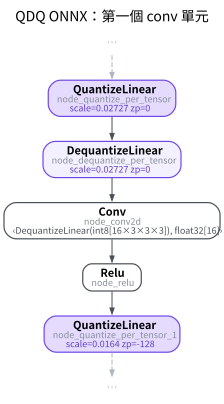

In [3]:
draw_onnx(onnx_model, focus="node_conv2d", hops=2, title="QDQ ONNX：第一個 conv 單元")

和 M01 看過的 Q/DQ 圖一模一樣，只是換了名字：`quantize_per_tensor` → `QuantizeLinear`，`dequantize_per_tensor` → `DequantizeLinear`，`conv2d` → `Conv`。weight 那一邊的 `DequantizeLinear(int8[…])` 只吃常數，所以收進 Conv 的標籤裡。

整張圖的對照：

In [4]:
PT2E_TO_ONNX = [
    ("quantize_per_tensor", "QuantizeLinear", "activation 的 fp32 → int8"),
    ("dequantize_per_tensor", "DequantizeLinear", "activation 的 int8 → fp32"),
    ("dequantize_per_channel", "DequantizeLinear", "weight 的 int8 → fp32；axis=0：每個輸出 channel 一組 scale"),
    ("conv2d", "Conv", ""),
    ("relu", "Relu", ""),
    ("max_pool2d", "MaxPool", ""),
    ("add", "Add", ""),
    ("adaptive_avg_pool2d", "ReduceMean", "輸出 1×1 的 adaptive pool 等於對 H、W 取平均"),
    ("flatten", "Reshape", ""),
    ("linear", "Gemm", ""),
]
pc, oc = op_counts(qdq), onnx_op_counts(onnx_model)
rows = [[p, pc.get(p, 0), o, oc.get(o, 0), note] for p, o, note in PT2E_TO_ONNX]
rows[2][2:4] = ["↑（同上）", ""]  # 兩種 dq 都變成 DequantizeLinear，個數合計在上一個 row
table(rows, ["Q/DQ 圖的 op", "個數", "ONNX op", "個數", "說明"])

Q/DQ 圖的 op,個數,ONNX op,個數,說明
quantize_per_tensor,11,QuantizeLinear,11,activation 的 fp32 → int8
dequantize_per_tensor,12,DequantizeLinear,16,activation 的 int8 → fp32
dequantize_per_channel,5,↑（同上）,,weight 的 int8 → fp32；axis=0：每個輸出 channel 一組 scale
conv2d,4,Conv,4,
relu,4,Relu,4,
max_pool2d,2,MaxPool,2,
add,1,Add,1,
adaptive_avg_pool2d,1,ReduceMean,1,輸出 1×1 的 adaptive pool 等於對 H、W 取平均
flatten,1,Reshape,1,
linear,1,Gemm,1,


每個 op 一對一變成 ONNX 的標準 op，Q/DQ 的位置原封不動。這種寫法叫 **QDQ format**：量化資訊全寫在 `QuantizeLinear`／`DequantizeLinear` 上，運算 op 本身仍是 fp32 的 `Conv`、`Gemm`。

只有一個數字對不上：`DequantizeLinear` 比 Q/DQ 圖的兩種 dq 加起來少。看殘差的 `Add` 附近：

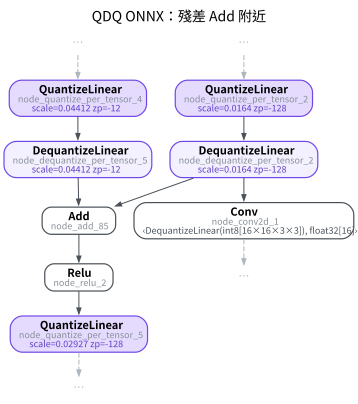

In [5]:
draw_onnx(onnx_model, focus=lambda n: n.op_type == "Add", hops=2, title="QDQ ONNX：殘差 Add 附近")

In [6]:
n_dq = pc["dequantize_per_tensor"] + pc["dequantize_per_channel"]
print(f"Q/DQ 圖的 dq：{n_dq} 個；QDQ ONNX 的 DequantizeLinear：{oc['DequantizeLinear']} 個")
assert oc["DequantizeLinear"] < n_dq

Q/DQ 圖的 dq：17 個；QDQ ONNX 的 DequantizeLinear：16 個


右邊那個 `DequantizeLinear` 同時給 `Add` 和下一個 `Conv` 用。`convert_pt2e` 原本替每個使用者各複製一個 dq（`DuplicateDQPass`，M02-3），`torch.onnx.export` 預設的圖最佳化又把兩個相同的 dq 合併回一個。M09-2 會看到 ORT 建 session 時再把它拆開。

## B. 檔案裡存了什麼

ONNX 把常數存成 **initializer**。依用途分組：

In [7]:
def role(op_type, idx):
    """initializer 是某個 op 的第 idx 個輸入 → 它的用途。"""
    if op_type == "DequantizeLinear":
        return ["weight（int8）", "weight 的 per-channel scale", "weight 的 zero_point"][idx]
    if op_type in ("Conv", "Gemm") and idx == 2:
        return "conv／linear 的 bias"
    return {"ReduceMean": "ReduceMean 的 axes", "Reshape": "Reshape 的目標 shape"}.get(op_type, f"{op_type} 的參數")


roles = {}
for n in onnx_model.graph.node:
    for idx, name in enumerate(n.input):
        roles.setdefault(name, role(n.op_type, idx))
groups, n_scalar = {}, 0
for init in onnx_model.graph.initializer:
    arr = numpy_helper.to_array(init)
    if arr.size == 1:
        n_scalar += 1
        continue
    g = groups.setdefault(roles[init.name], [str(arr.dtype), 0, []])
    g[1] += 1
    g[2].append("×".join(map(str, arr.shape)))
rows = [[r, dt, cnt, "、".join(shapes[:3]) + ("…" if len(shapes) > 3 else "")] for r, (dt, cnt, shapes) in groups.items()]
rows.append(["activation 的 scale／zero_point", "float32／int8", n_scalar, "純量"])
table(rows, ["用途", "dtype", "個數", "shape"])

用途,dtype,個數,shape
conv／linear 的 bias,float32,5,16、16、16…
weight（int8）,int8,5,16×3×3×3、16×16×3×3、16×16×3×3…
weight 的 per-channel scale,float32,5,16、16、16…
weight 的 zero_point,int8,3,16、32、4
ReduceMean 的 axes,int64,1,2
Reshape 的目標 shape,int64,1,2
activation 的 scale／zero_point,float32／int8,11,純量


In [8]:
assert groups["weight（int8）"][0] == "int8" and groups["conv／linear 的 bias"][0] == "float32"

- int8 weight 是 `convert_pt2e` 已經量化好的常數（M02-3），匯出時原樣寫進檔案；每個輸出 channel 一個 scale。
- weight 是對稱量化，zero point 全是 0；內容相同的 zero point 只存一份（同樣 channel 數的 weight 共用），所以個數比 weight 少。
- bias 在 Q/DQ 圖上沒有量化，所以檔案裡仍是 float32。

檔案裡有 int8 weight，但**這個檔案本身沒有任何 int8 kernel**：`Conv` 仍是 fp32 的 op，要不要換成 int8 kernel，由執行它的 ORT 決定（M09-2）。

把 fp32 模型也匯出一份，拆開比較兩個檔案的大小：

In [9]:
def sizes(name, m):
    """(.onnx 總大小, initializer, node, 其中 node 的 metadata_props)，單位 bytes。"""
    init = sum(len(i.SerializeToString()) for i in m.graph.initializer)
    nodes = sum(len(n.SerializeToString()) for n in m.graph.node)
    meta = sum(len(p.SerializeToString()) + 2 for n in m.graph.node for p in n.metadata_props)
    return [name, len(m.SerializeToString()), init, nodes, meta]


rows = [sizes("torch.onnx.export(fp32 模型)（to_onnx）", to_onnx(model, x)), sizes("torch.onnx.export(Q/DQ 圖)", onnx_model)]
table(rows, ["", "總計", "initializer", "node", "node 裡的 metadata_props"])

,總計,initializer,node,node 裡的 metadata_props
torch.onnx.export(fp32 模型)（to_onnx）,59195,39795,15693,13995
torch.onnx.export(Q/DQ 圖),66019,11112,47638,42519


In [10]:
init_ratio, total_ratio = rows[1][2] / rows[0][2], rows[1][1] / rows[0][1]
print(f"initializer 變成 fp32 的 {init_ratio:.0%}；檔案總大小是 fp32 的 {total_ratio:.0%}")
if total_ratio > 1:
    print("檔案反而變大：多出來的 QuantizeLinear／DequantizeLinear node，各帶一份 metadata_props。")
assert init_ratio < 0.5

initializer 變成 fp32 的 28%；檔案總大小是 fp32 的 112%
檔案反而變大：多出來的 QuantizeLinear／DequantizeLinear node，各帶一份 metadata_props。


weight 從 4 bytes 變 1 byte，initializer 大幅縮小。但 `torch.onnx.export` 在每個 node 的 `metadata_props` 寫了來源資訊（原本的 fx node、module 路徑），Q/DQ 又多出一大堆 node；這個小模型的 node 比 weight 還占空間。模型越大，weight 的占比越高（推論，沒有量更大的模型）。

## C. 動態 batch

Q/DQ 圖的第一步是 `torch.export.export(..., dynamic_shapes=({0: Dim.AUTO},))`（包在 `export_module`），batch 維度是動態的。同一張 Q/DQ 圖匯出兩次，差別只在有沒有傳 `dynamic_shapes`；各建一個 `ort.InferenceSession`（`ort_session`），餵兩種 batch：

In [11]:
rows, dim0 = [], {}
for dynamic in [False, True]:
    m = to_onnx(qdq, x, dynamic_batch=dynamic)
    d = m.graph.input[0].type.tensor_type.shape.dim[0]
    dim0[dynamic] = d.dim_param or d.dim_value
    sess = ort_session(m)
    results = []
    for bs in [x[0].shape[0], 4]:
        try:
            ort_run(sess, torch.randn(bs, 3, 16, 16))
            results.append(f"batch {bs} OK")
        except Exception as e:  # ORT 的 shape 錯誤是 InvalidArgument
            results.append(f"batch {bs} {type(e).__name__}")
    rows.append(['dynamic_shapes=({0: Dim("batch")},)' if dynamic else "不傳 dynamic_shapes", dim0[dynamic], "；".join(results)])
table(rows, ["torch.onnx.export(Q/DQ 圖, x, dynamo=True, …)", "輸入的第 0 維", "ORT 執行"])

"torch.onnx.export(Q/DQ 圖, x, dynamo=True, …)",輸入的第 0 維,ORT 執行
不傳 dynamic_shapes,2,batch 2 OK；batch 4 InvalidArgument
"dynamic_shapes=({0: Dim(""batch"")},)",batch,batch 2 OK；batch 4 OK


In [12]:
assert dim0[False] == x[0].shape[0] and isinstance(dim0[True], str)

`torch.onnx.export(dynamo=True)` 會拿 `x` 重新 `torch.export` 一次，所以不傳 `dynamic_shapes` 時，第 0 維被寫死成 `x` 的 batch，GraphModule 原本的動態 batch 沒有帶過來。傳了 `dynamic_shapes`，第 0 維變成符號，ORT 接受任何 batch。本章之後都這樣匯出（`to_onnx` 預設 `dynamic_batch=True`）。

## 小結

- Q/DQ 圖匯出成 ONNX 後結構不變：q/dq 變成 `QuantizeLinear`／`DequantizeLinear`，其他 op 換成 ONNX 的標準 op。這就是 QDQ format。
- 檔案裡 weight 是 int8 + per-channel scale，bias 仍是 fp32；這個檔案還沒有任何 int8 kernel。
- 動態 batch 要在 `torch.onnx.export` 再講一次。
- 要不要把「DequantizeLinear → Conv → QuantizeLinear」換成 int8 kernel，由執行它的 ORT 決定（M09-2）。